In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

from lightgbm import LGBMClassifier

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)


In [3]:
DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

assert len(df) == 307511
assert df["SK_ID_CURR"].is_unique

print("Dataset:", df.shape)
print("Positive rate:", round(df["TARGET"].mean(), 4))

Dataset: (307511, 143)
Positive rate: 0.0807


In [4]:
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "credit_income_ratio",
    "annuity_income_ratio",
    "employment_years",
    "employment_sentinel_flag",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "has_bureau_history",
    "bureau_total_accounts",
    "bureau_active_accounts",
    "bureau_closed_accounts",
    "bureau_total_credit",
    "bureau_total_debt",
    "bureau_total_overdue",
    "bureau_max_days_overdue",
    "bureau_avg_days_since_credit",
    "bureau_debt_credit_ratio"
]

categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY"
]

all_features = numeric_features + categorical_features

X = df[all_features].copy()
y = df["TARGET"].astype(int)

X[numeric_features] = X[numeric_features].replace(
    [np.inf, -np.inf],
    np.nan
)

assert not X.columns.duplicated().any()
assert "TARGET" not in X.columns
assert "SK_ID_CURR" not in X.columns

print("Total features:", len(all_features))

Total features: 27


In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 184506
Validation: 61502
Test: 61503


In [6]:
def make_preprocessor(num_cols, cat_cols):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, num_cols),
            ("cat", categorical_pipeline, cat_cols)
        ],
        sparse_threshold=1.0
    )

In [7]:
def make_lightgbm():
    return LGBMClassifier(
        objective="binary",
        metric="auc",
        n_estimators=524,
        learning_rate=0.04,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=80,
        colsample_bytree=0.8,
        subsample=0.8,
        subsample_freq=1,
        reg_lambda=2.0,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

In [8]:
def get_metrics(y_true, probabilities):
    return {
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        )
    }

In [9]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print(f"Running fold {fold}...")

    X_fold_train = X_train.iloc[train_idx]
    X_fold_valid = X_train.iloc[valid_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    # Fit preprocessing separately within each fold
    prep = make_preprocessor(
        numeric_features,
        categorical_features
    )

    X_fold_train_p = prep.fit_transform(X_fold_train)
    X_fold_valid_p = prep.transform(X_fold_valid)

    model = make_lightgbm()

    model.fit(X_fold_train_p, y_fold_train)

    probabilities = model.predict_proba(
        X_fold_valid_p
    )[:, 1]

    metrics = get_metrics(y_fold_valid, probabilities)

    cv_results.append({
        "Fold": fold,
        **metrics
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

Running fold 1...


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Running fold 2...


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Running fold 3...


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Fold,ROC-AUC,Average Precision,Brier Score
0,1,0.7476,0.2286,0.0685
1,2,0.7488,0.2343,0.0683
2,3,0.7434,0.2322,0.0685


In [10]:
metric_cols = [
    "ROC-AUC",
    "Average Precision",
    "Brier Score"
]

cv_summary = cv_df[metric_cols].agg(["mean", "std"])

display(cv_summary.round(4))

,ROC-AUC,Average Precision,Brier Score
mean,0.7466,0.2317,0.0684
std,0.0028,0.0028,0.0001


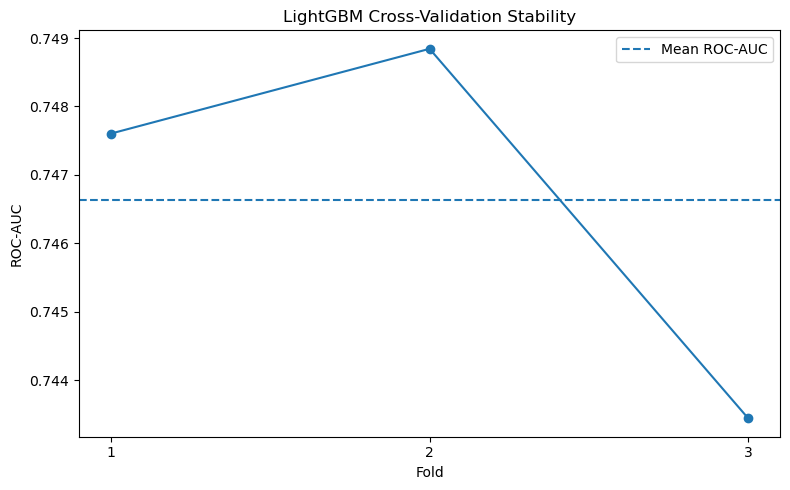

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    cv_df["Fold"],
    cv_df["ROC-AUC"],
    marker="o"
)

ax.axhline(
    cv_df["ROC-AUC"].mean(),
    linestyle="--",
    label="Mean ROC-AUC"
)

ax.set_title("LightGBM Cross-Validation Stability")
ax.set_xlabel("Fold")
ax.set_ylabel("ROC-AUC")
ax.set_xticks([1, 2, 3])
ax.legend()

plt.tight_layout()
plt.show()

In [12]:
prep = make_preprocessor(
    numeric_features,
    categorical_features
)

X_train_p = prep.fit_transform(X_train)
X_val_p = prep.transform(X_val)

model = make_lightgbm()
model.fit(X_train_p, y_train)

train_prob = model.predict_proba(X_train_p)[:, 1]
val_prob = model.predict_proba(X_val_p)[:, 1]

train_metrics = get_metrics(y_train, train_prob)
val_metrics = get_metrics(y_val, val_prob)

overfit_df = pd.DataFrame({
    "Training": train_metrics,
    "Validation": val_metrics
}).T

display(overfit_df.round(4))

print(
    "ROC-AUC gap:",
    round(
        train_metrics["ROC-AUC"] -
        val_metrics["ROC-AUC"], 4
    )
)

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,ROC-AUC,Average Precision,Brier Score
Training,0.7852,0.2854,0.0660
Validation,0.7541,0.2373,0.0681


ROC-AUC gap: 0.0311


In [13]:
bureau_features = [
    col for col in numeric_features
    if col.startswith("bureau_")
    or col == "has_bureau_history"
]

application_numeric = [
    col for col in numeric_features
    if col not in bureau_features
]

print("Application numeric:", len(application_numeric))
print("Bureau features:", len(bureau_features))

print("Bureau features:")
print(bureau_features)

Application numeric: 12
Bureau features: 10
Bureau features:
['has_bureau_history', 'bureau_total_accounts', 'bureau_active_accounts', 'bureau_closed_accounts', 'bureau_total_credit', 'bureau_total_debt', 'bureau_total_overdue', 'bureau_max_days_overdue', 'bureau_avg_days_since_credit', 'bureau_debt_credit_ratio']


In [14]:
feature_sets = {
    "Application Only": (
        application_numeric,
        categorical_features
    ),
    "Application + Bureau": (
        numeric_features,
        categorical_features
    )
}

ablation_results = []

for experiment_name, (num_cols, cat_cols) in feature_sets.items():

    selected_cols = num_cols + cat_cols
    X_selected = X_train[selected_cols]

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_selected, y_train), start=1
    ):
        print(f"{experiment_name} — Fold {fold}")

        X_fold_train = X_selected.iloc[train_idx]
        X_fold_valid = X_selected.iloc[valid_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        prep_fold = make_preprocessor(
            num_cols,
            cat_cols
        )

        train_p = prep_fold.fit_transform(X_fold_train)
        valid_p = prep_fold.transform(X_fold_valid)

        fold_model = make_lightgbm()
        fold_model.fit(train_p, y_fold_train)

        probabilities = fold_model.predict_proba(
            valid_p
        )[:, 1]

        metrics = get_metrics(
            y_fold_valid,
            probabilities
        )

        ablation_results.append({
            "Experiment": experiment_name,
            "Fold": fold,
            **metrics
        })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

Application Only — Fold 1


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Application Only — Fold 2


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Application Only — Fold 3


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (3 outputs left out)

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Application + Bureau — Fold 3


/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Experiment,Fold,ROC-AUC,Average Precision,Brier Score
0,Application Only,1,0.7417,0.2181,0.0689
1,Application Only,2,0.7421,0.2230,0.0687
2,Application Only,3,0.7366,0.2194,0.0690
3,Application + Bureau,1,0.7476,0.2286,0.0685
4,Application + Bureau,2,0.7488,0.2343,0.0683
5,Application + Bureau,3,0.7434,0.2322,0.0685


In [15]:
ablation_summary = (
    ablation_df
    .groupby("Experiment")[
        ["ROC-AUC", "Average Precision", "Brier Score"]
    ]
    .agg(["mean", "std"])
)

display(ablation_summary.round(4))

ROC-AUC         Average Precision         Brier Score  \
                        mean     std              mean     std        mean   
Experiment                                                                   
Application + Bureau  0.7466  0.0028            0.2317  0.0028      0.0684   
Application Only      0.7401  0.0031            0.2202  0.0026      0.0689   

                              
                         std  
Experiment                    
Application + Bureau  0.0001  
Application Only      0.0001

In [16]:
full = (
    ablation_df[
        ablation_df["Experiment"] == "Application + Bureau"
    ]
    .set_index("Fold")
)

basic = (
    ablation_df[
        ablation_df["Experiment"] == "Application Only"
    ]
    .set_index("Fold")
)

improvement = (
    full[["ROC-AUC", "Average Precision", "Brier Score"]]
    - basic[["ROC-AUC", "Average Precision", "Brier Score"]]
)

display(improvement.round(4))

print("Mean difference (full minus application-only):")
display(improvement.mean().round(4))

,ROC-AUC,Average Precision,Brier Score
Fold,,,
1,0.0059,0.0105,-0.0004
2,0.0067,0.0112,-0.0005
3,0.0069,0.0128,-0.0005


Mean difference (full minus application-only):


ROC-AUC              0.0065
Average Precision    0.0115
Brier Score         -0.0005
dtype: float64

In [17]:
train_ids = set(df.loc[X_train.index, "SK_ID_CURR"])
val_ids = set(df.loc[X_val.index, "SK_ID_CURR"])
test_ids = set(df.loc[X_test.index, "SK_ID_CURR"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_ids | val_ids | test_ids) == len(df)

print("PASS: No overlap between data partitions.")

PASS: No overlap between data partitions.


In [18]:
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(
        name,
        "positive rate:",
        round(target.mean() * 100, 2),
        "%"
    )

Train positive rate: 8.07 %
Validation positive rate: 8.07 %
Test positive rate: 8.07 %


In [19]:
cv_df.to_csv(
    REPORT_DIR / "day07_cross_validation.csv",
    index=False
)

overfit_df.to_csv(
    REPORT_DIR / "day07_overfitting_analysis.csv"
)

ablation_df.to_csv(
    REPORT_DIR / "day07_feature_ablation.csv",
    index=False
)

ablation_summary.to_csv(
    REPORT_DIR / "day07_ablation_summary.csv"
)

print("Day 7 results exported.")

Day 7 results exported.
